# Which physical laws can LC-AFM condition on?

**LC-AFM** (law-conditioned adaptive flow matching) keeps the AFM network, loss and sampler and changes only the
flow's starting point. AFM starts from the encoder estimate plus white noise, $x_0 = E + \sigma\varepsilon$; LC-AFM
starts from a Gaussian **conditioned on linear physical laws** $Jx \approx b$ with a tolerance $\tau$. Both the mean and
the noise of the base then respect the laws, as strictly as the tolerance allows, and the flow learns the rest,
including everything non-Gaussian. This notebook tests candidate laws on the regional climate model's (RCM) own
output, before any training, against three criteria:

* **(a) Does the law hold?** On the training years, on unseen years, in a warmer climate (2041–2060, 2080–2099) and
  with predictors from the driving global model (GCM). Measured by calibration (mean $z^2 = 1$ when the tolerance is
  right) and drift (a non-zero mean residual in another climate).
* **(b) Does conditioning change the base?** White noise destroys every structure, including the climatological one,
  so a white base violates even laws that the encoder knows. The stronger a white base violates a law (relative to
  the truth), the more the conditioning reshapes the noise. This is the go/no-go test of the plan.
* **(c) Does the law add daily information?** Whether the law also improves the base's *mean* beyond what the encoder
  already knows: skill beyond the training climatology (a weak baseline), and the conditioned encoder mean against the
  encoder itself.

Two remarks on the design:

* **Residuals need not be Gaussian.** The base is Gaussian by construction and the flow learns the non-Gaussian part.
  With the right second moments (tolerance and prior variance) the Gaussian posterior mean is the best *linear*
  combination of encoder and law whatever the error distribution, so calibration matters, the shape of the residuals
  much less. The shape would matter for sampler guidance with the exact law as a likelihood.
* **Oracle tests.** Fields that LC-AFM would generate jointly with pr and tasmax (wind, humidity, pressure, other
  temperatures) are taken from the RCM itself. The results are therefore an upper bound for joint downscaling; coarse
  inputs are the benchmark's 2° predictors, as at test time.

**Data.** Benchmark: ALPS, ESD pseudo-reality, ALADIN63 driven by CNRM-CM5, 128 × 128 at 12.5 km, predictors u, v, t, z, q
at 850/700/500 hPa on a 16 × 16 grid at 2°. Extra 12 km fields of the same RCM run from the DKRZ CORDEX archive
(`dslab extract`; its precipitation equals the benchmark's target exactly) and the driving GCM's daily pr and tas from
the CMIP5 archive, regridded conservatively to the 2° grid (`dslab extract --gcm`).

**Run it:** JupyterHub (kernel **dslab**) or `sbatch jobs/notebook.sbatch notebooks/laws.ipynb`; it only loads
precomputed results.

In [1]:
%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm

from dslab import candidate_laws as CL
from dslab import plotting as P
from dslab.experiment import Experiment
from dslab.law_diagnostics import summary

EXP = Experiment.load("alps_esd")
D = EXP.eval_dir / "laws"
D1 = xr.open_dataset(D / "diagnostics.nc")   # LC-AFM laws T, Tfull, O
DC = xr.open_dataset(D / "candidates.nc")    # candidate laws
common = [v for v in D1.data_vars if v in DC.data_vars]
ALL = xr.concat([D1[common].drop_vars(["law_highpass"], errors="ignore"), DC[common]], dim="law", coords="minimal",
                compat="override", join="override")
INFO = {**json.loads(D1.attrs["law_info"]), **json.loads(DC.attrs["law_info"])}
ALL.attrs["law_info"] = json.dumps(INFO)
SUM = summary(ALL)
CONS = pd.read_csv(D / "consistency.csv")
CP = pd.read_csv(D / "counterparts.csv")
PRIM = pd.read_csv(D / "primitive.csv")
VAL = pd.read_csv(D / "law_value.csv")
NOISE = {**json.loads(D1.attrs["noise_levels"]), **json.loads(DC.attrs["noise_levels"])}
SPLITS = list(ALL.split.values)
GROUPS = {"temperature": ["Tfull", "T", "Tfull_tas", "Tfull_tasmin", "D", "Hyd"],
          "humidity": ["Qfull"],
          "dynamics: coarse consistency": ["C_u850", "C_v850", "C_z500"],
          "precipitation": ["O", "U_lin", "U_pos", "U_pos_40km", "M", "M_40km", "M_Efit", "CC", "CC0"]}
UNITS_T = {"tas": "K", "tasmin": "K", "tasmax": "K", "pr": "mm/day", "lnpr_wet": "ln(mm/day)", "huss": "kg/kg",
           "zg500": "m", "cellmean:ua850": "m/s", "cellmean:va850": "m/s", "cellmean:zg500": "m"}
for n in CL.LAWS:  # short titles and units for the figures
    P.LAW_TITLES[n] = CL.LAWS[n]["title"]
    P.LAW_UNITS[n] = UNITS_T[CL.LAWS[n]["target"]]
MG = P.MapGrid(ALL, EXP.grid_crs)
FIG_DIR = D / "figures"
FIG_DIR.mkdir(exist_ok=True)
save = lambda name: FIG_DIR / f"{name}.png"  # noqa: E731
GREY = LinearSegmentedColormap.from_list("grey", P.GREY_RAMP)
P.setup_style()


def caption(shown, evaluated):
    display(Markdown(f"**Shown:** {shown}  \n**Laws fitted on:** the training years 1961–1980 (without 1967 and "
                     f"1975), RCM truth and predictors  \n**Evaluated on:** {evaluated}"))


def fmt(v):
    return "" if pd.isna(v) else f"{v:.3g}" if abs(v) < 1e-2 and v != 0 else f"{v:.3f}" if abs(v) < 10 else f"{v:.1f}"


print("laws:", list(ALL.law.values))

/tmp/ipykernel_3715233/3685100184.py:21: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ALL = xr.concat([D1[common].drop_vars(["law_highpass"], errors="ignore"), DC[common]], dim="law", coords="minimal",


laws: [np.str_('T'), np.str_('Tfull'), np.str_('O'), np.str_('Tfull_tas'), np.str_('Tfull_tasmin'), np.str_('D'), np.str_('U_lin'), np.str_('U_pos'), np.str_('M'), np.str_('Qfull'), np.str_('Hyd'), np.str_('C_u850'), np.str_('C_v850'), np.str_('C_z500'), np.str_('U_pos_40km'), np.str_('M_40km'), np.str_('M_Efit'), np.str_('CC'), np.str_('CC0')]


## 1. The variables and their 2° counterparts

A coarse-consistency law $A\,x = y$ (the 2° area mean of a 12 km field equals its coarse counterpart) needs that
counterpart at test time. In this benchmark the **only** coarse inputs are the 15 predictors, so only fields that
are themselves predictors have one:

| 12 km field | coarse counterpart, perfect predictors | coarse counterpart, GCM predictors | in the benchmark? |
|---|---|---|---|
| `ua850`, `va850`, `zg500` | `u_850`, `v_850`, `z_500` (the RCM regridded) | the GCM's fields | **yes** (predictors) |
| `pr` | the RCM's own 2° precipitation | the GCM's daily pr (CMIP5 archive) | no |
| `tas` | the RCM's own 2° mean | the GCM's daily tas | no |
| `tasmax`, `tasmin`, `huss` | the RCM's own 2° mean | not archived for this GCM | no |

**Precipitation and near-surface temperature have no coarse counterpart in the benchmark, by design.** Statistical
downscaling under "perfect prognosis" uses predictors that global models simulate well (free-atmosphere circulation,
temperature, humidity) and avoids their surface precipitation, which is parameterised and biased. Coarse consistency
for pr or tasmax is still possible: in the perfect-predictor setting the counterpart is the RCM's own 2° field, and
with imperfect predictors it is the GCM's. Using either means adding an input the benchmark entries do not have,
which changes the task (towards super-resolution of precipitation) and its comparability. The table below shows
what such a law would pin and how far the GCM's counterpart is from the RCM's.

In [2]:
caption("share of each 12 km field's daily variability (anomalies about the period's own monthly climatology) "
        "held by its 2° cell means, i.e. what an exact coarse-consistency law would pin with perfect predictors; and "
        "the same share for the climate-change signal (the period's monthly climatology minus the training years').",
        "the 12 km points of the 53 full 2° cells inside the window, four 20-year periods")
rcm = CP[CP.counterpart.str.startswith("RCM")]
pin = rcm.pivot_table(index="field", columns="split", values="share of daily variance at 2°", sort=False)
display(pin.rename(columns=P.SPLIT_LABELS).style.format("{:.2f}").set_caption("share of the daily variability at 2°"))
chg = rcm.dropna(subset=["share of the change at 2°"]).pivot_table(
    index="field", columns="split", values=["mean change", "share of the change at 2°"], sort=False)
display(chg.rename(columns=P.SPLIT_LABELS).style.format(fmt).set_caption(
    "climate-change signal against 1961–1980: domain-mean change and its share at 2°"))
caption("the GCM's daily field on the 2° grid against the RCM's 2° area mean: bias, RMSE relative to the RCM's daily "
        "variability, correlation of the daily values and of their anomalies.", "53 full 2° cells, four 20-year periods")
gcm = CP[CP.counterpart.str.startswith("GCM")].set_index(["field", "split"])[
    ["bias", "RMSE", "relative RMSE", "corr", "corr of daily anomalies"]]
display(gcm.rename(index=P.SPLIT_LABELS).style.format(fmt).set_caption("GCM vs. RCM on the 2° grid"))

**Shown:** share of each 12 km field's daily variability (anomalies about the period's own monthly climatology) held by its 2° cell means, i.e. what an exact coarse-consistency law would pin with perfect predictors; and the same share for the climate-change signal (the period's monthly climatology minus the training years').  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** the 12 km points of the 53 full 2° cells inside the window, four 20-year periods

split,training years 1961–80,1981–2000,2041–2060,2080–2099
field,,,,
pr,0.61,0.61,0.61,0.62
tasmax,0.89,0.89,0.89,0.89
tas,0.92,0.92,0.92,0.92
tasmin,0.87,0.87,0.87,0.88
huss,0.90,0.90,0.90,0.89
ua850,0.93,0.93,0.93,0.93
va850,0.94,0.94,0.94,0.94
zg500,0.99,0.99,0.99,0.99


**Shown:** the GCM's daily field on the 2° grid against the RCM's 2° area mean: bias, RMSE relative to the RCM's daily variability, correlation of the daily values and of their anomalies.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** 53 full 2° cells, four 20-year periods

,,bias,RMSE,relative RMSE,corr,corr of daily anomalies
field,split,,,,,
pr,training years 1961–80,-0.744,5.171,1.000,0.411,0.378
tas,training years 1961–80,0.678,2.676,0.905,0.952,0.710
pr,1981–2000,-0.725,5.165,0.991,0.422,0.392
tas,1981–2000,0.649,2.461,0.861,0.958,0.739
pr,2041–2060,-0.691,5.547,1.004,0.404,0.368
tas,2041–2060,0.612,2.505,0.893,0.955,0.715
pr,2080–2099,-0.606,5.717,1.004,0.409,0.374
tas,2080–2099,0.524,2.477,0.863,0.956,0.708


**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **No coarse counterpart in the benchmark** for pr, tas, tasmax, tasmin or huss: the 15 predictors are
  free-atmosphere fields only (perfect prognosis). Only `ua850`, `va850` and `zg500` have one (`u_850`, `v_850`, `z_500`).
* **What an exact coarse-consistency law would pin** (perfect counterpart, the RCM's own 2° mean): 61–62% of the daily
  variability of 12 km precipitation, 87–92% for the three temperatures, 89–90% for `huss`, 93–94% for the 850 hPa
  wind and 99% for `zg500`, in every period. Of the climate-change signal by 2080–2099 it holds 74% for pr and 99%
  for the temperatures and humidity. For comparison, the best predictor-based precipitation law explains ≤ 5% (12 km)
  and ≤ 18% (40 km) of the daily variability (section 6): **a coarse counterpart is by far the strongest precipitation
  law**, and for tasmax it would fix the warming signal, whose error dominates AFM's end-century summer bias (about
  −3 K in July–August, evaluation notebook).
* **The GCM is a poor counterpart.** Its 2° precipitation is 0.6–0.7 mm/day drier than the RCM's, its daily error is
  as large as the RCM's daily variability (relative RMSE 0.99–1.00) and the daily anomalies correlate 0.37–0.39; tas
  is 0.5–0.7 K warmer, relative RMSE 0.86–0.91, anomaly correlation 0.71–0.74. In this pseudo-reality the RCM develops
  its own weather inside the domain, so a coarse law with GCM fields would impose the GCM's weather. The same holds for
  the predictor fields (C with GCM predictors, section 4).
* **A decision, not a test result:** adding a coarse pr (or tas) input leaves the benchmark protocol. With the RCM's
  own 2° fields it gives an upper bound (super-resolution); with GCM fields it becomes bias adjustment plus
  downscaling, and the tolerance must cover the GCM–RCM mismatch.

## 2. The laws: exact form and how we estimate it

Each law is written as it holds in a perfect environment, then as we estimate it from the available data. Every law
reads $\text{target} \approx \sum_k a_k\,\text{term}_k + c_m$ with a tolerance $\tau_m$ per grid point and calendar
month $m$; the offset $c_m$ and $\tau_m$ are fitted on the training truth so that the truth scores 1 there. Terms with a
fixed coefficient ($a_k = 1$) are exact physics; the others have one fitted coefficient.

**Temperature**
* **Tfull** (`tasmax`) and **Tfull_tas**, **Tfull_tasmin**: *exact*, hydrostatic balance fixes the free-atmosphere
  profile $T(z)$, and the 2 m temperature is that profile at the surface plus a boundary-layer departure.
  *Estimate:* $T_\text{free}$ from the coarse $t$, $z$ at 850/700/500 hPa, interpolated to the point and to its
  elevation (below 850 hPa with the 850–700 lapse rate); the boundary-layer departure is the offset $c_m$.
* **T**: Tfull on the sub-2° scales only: $H\,T_{\max} \approx H\,T_\text{free} + c_m$, with $H$ the high-pass that
  removes what the 2° grid resolves.
* **D**: *exact*, the daily mean is the time average of $T(t)$; it equals $(T_\max + T_\min)/2$ only for a symmetric
  diurnal cycle. *Estimate:* $T_\text{mean} \approx (T_\max + T_\min)/2 + c_m$; all three are generated fields.
* **Hyd** (a primitive equation, section 7): *exact*, the hydrostatic equation integrated from the surface,
  $z_{500} = z_s + \frac{R_d}{g}\int_{500}^{p_s} T_v\,d\ln p$. *Estimate:* $T_v(\ln p)$ piecewise linear through the
  surface value (generated `tas`, `huss`) and the coarse levels above the surface; generated `ps`; target the
  generated 12 km `zg500`.

**Humidity**
* **Qfull**: *exact in a well-mixed lower troposphere*, the near-surface humidity follows the free-atmosphere humidity
  profile at the surface height; departures come from evaporation and the boundary layer. *Estimate:* the coarse $q$,
  $z$ at 850/700/500 hPa interpolated to the elevation (as Tfull), target the generated 2 m humidity `huss`.
* **Moisture in this setup.** Humidity enters only as a predictor ($q$ at 850/700/500 hPa, 2°, daily). At 12 km the
  archive of this RCM run holds `huss` (daily, 3-hourly), relative humidity and evaporation, but **no humidity on
  pressure levels, no column water vapour (`prw`) and no moisture flux**; the only 12 km upper-air fields are
  `ua850`, `va850`, `zg500` (and 200 hPa winds). The column budget (law M) can therefore be closed only for a surface
  layer plus the coarse $q_{850}$ (section 2, Precipitation), and at 2° for the 850–500 hPa layer (section 7, P-hum).
  Conditioning on moisture itself would mean generating `huss` (law Qfull, coarse consistency of `huss`, section 1).

**Dynamics: coarse consistency**
* **C_u850, C_v850, C_z500**: *exact*, the perfect predictors are the RCM's own fields regridded conservatively to 2°,
  $A\,x = y$. *Estimate:* the area mean over the 12 km points of each 2° cell lying entirely inside the window (53 of
  the 92 cells the window touches), skipping points where 850 hPa is below ground; shown piecewise constant per cell.

**Precipitation**
* **O**: Smith & Barstad (2004) linear orographic precipitation on the sub-2° terrain, with the day's coarse 700 hPa
  wind, stability and moisture: $H\,P \approx H\,P_{SB}(h') + c_m$ (an LC-AFM law, part 1 of the earlier analysis).
* **U** (terrain-forced ascent): *exact*, the kinematic boundary condition $w_s = \mathbf V_s\cdot\nabla h$; saturated
  air lifted at $w$ condenses $C_w\,w$ ($C_w = \rho_s\Gamma_m/\gamma$), and in the upslope limit all of it falls out:
  $P = C_w(\mathbf V_s\cdot\nabla h)_+$. *Estimate:* **U_lin** $P \approx a\,C_w\,(\overline{\mathbf V}_{10m}\cdot\nabla h) +
  c_m$ (daily-mean wind, no positive part: linear in the wind); **U_pos** with the 6-hourly positive part; **U_pos_40km**
  with both sides smoothed to ~40 km. The 10 m wind stands in for the wind at the condensation level; the efficiency
  $a$ is fitted; condensate drift and fall-out time are ignored.
* **M** (moisture conservation): *exact*, the column water-vapour budget $P - E = -\partial_t W - \nabla\cdot\mathbf Q$,
  $W = \frac1g\int_0^{p_s} q\,dp$, $\mathbf Q = \frac1g\int_0^{p_s} q\,\mathbf V\,dp$ (daily mean of the instantaneous flux).
  *Estimate:* no column water or flux is archived, so two layers with fitted effective masses $a_s$, $a_{850}$:
  $P \approx E + a_s(-\nabla\cdot\langle q_s\mathbf V_{10m}\rangle - \partial_t q_s) + a_{850}(-\nabla\cdot(\hat q_{850}
  \overline{\mathbf V}_{850})) + c_m$ (6-hourly surface products; coarse $q_{850}$ times the daily fine 850 hPa wind).
  **M_40km**: both sides smoothed to ~40 km; **M_Efit**: evaporation coefficient fitted instead of 1.
* **CC** (Clausius–Clapeyron): *exact*, $d\ln e_s/dT = L_v/(R_vT^2)$, about 7%/K; precipitation follows it only if the
  condensing motion is unchanged. *Estimate:* on wet days ($P \ge 1$ mm/day) $\ln P \approx c_m + \beta_m T_{850}$ with
  the coarse 850 hPa temperature and $\beta_m = L_v/(R_v\bar T^2)$. **CC0** is the reference without the term (the
  monthly climatology of $\ln P$).

**Linearity.** LC-AFM conditions a Gaussian on $Jx \approx b$, so a law must be linear in the *generated* fields
(predictor-only factors may enter $J$ and $b$ freely). The last column of the table says which laws are; the
others need a linearisation about the encoder estimate, re-done per sample or per flow step.

In [3]:
LINEAR = {"Tfull": "yes", "T": "yes", "Tfull_tas": "yes", "Tfull_tasmin": "yes",
          "D": "yes (tas, tasmax, tasmin jointly)", "Hyd": "after linearisation (T_v, ln p_s)", "Qfull": "yes",
          "C_u850": "yes", "C_v850": "yes", "C_z500": "yes", "O": "yes",
          "U_lin": "yes (pr and the 10 m wind jointly)", "U_pos": "no (positive part of the wind term)",
          "U_pos_40km": "no (positive part)", "M": "if the fluxes <q V> are generated channels; ∂W/∂t needs neighbouring days",
          "M_40km": "as M", "M_Efit": "as M", "CC": "no (ln P on wet days)", "CC0": "no (ln P on wet days)"}
rows = []
for g, laws in GROUPS.items():
    for n in laws:
        i = INFO[n]
        coef = i.get("coef") or {}
        if "hw" in i:
            coef = {"H_w (m)": i["hw"], "τ_c (s)": i["tau_c"], "τ_f (s)": i["tau_f"], "gain": i["gain"]}
        rows.append({"group": g, "law": n, "target": i.get("target", i.get("variable")),
                     "fitted coefficients": ", ".join(f"{k} = {v:.3g}" for k, v in coef.items()),
                     "RMS tolerance τ": i["rms_tolerance"], "linear in the generated fields": LINEAR[n]})
display(pd.DataFrame(rows).set_index(["group", "law"]).style.format({"RMS tolerance τ": fmt}))

## 3. The three criteria at a glance

**Shown:** one row per law; (a) mean squared normalised residual of the truth (1 = tolerance calibrated); (b) the same for a white base: truth plus white noise at the conservative noise proxy (hollow) and the trained AFM's white base E + σε (filled, pr and tasmax laws); (c) variance explained beyond the training-years monthly climatology. Values outside the axes are printed.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** 1981–2000 and 2080–2099 (RCM predictors), 1981–2000 (GCM predictors)

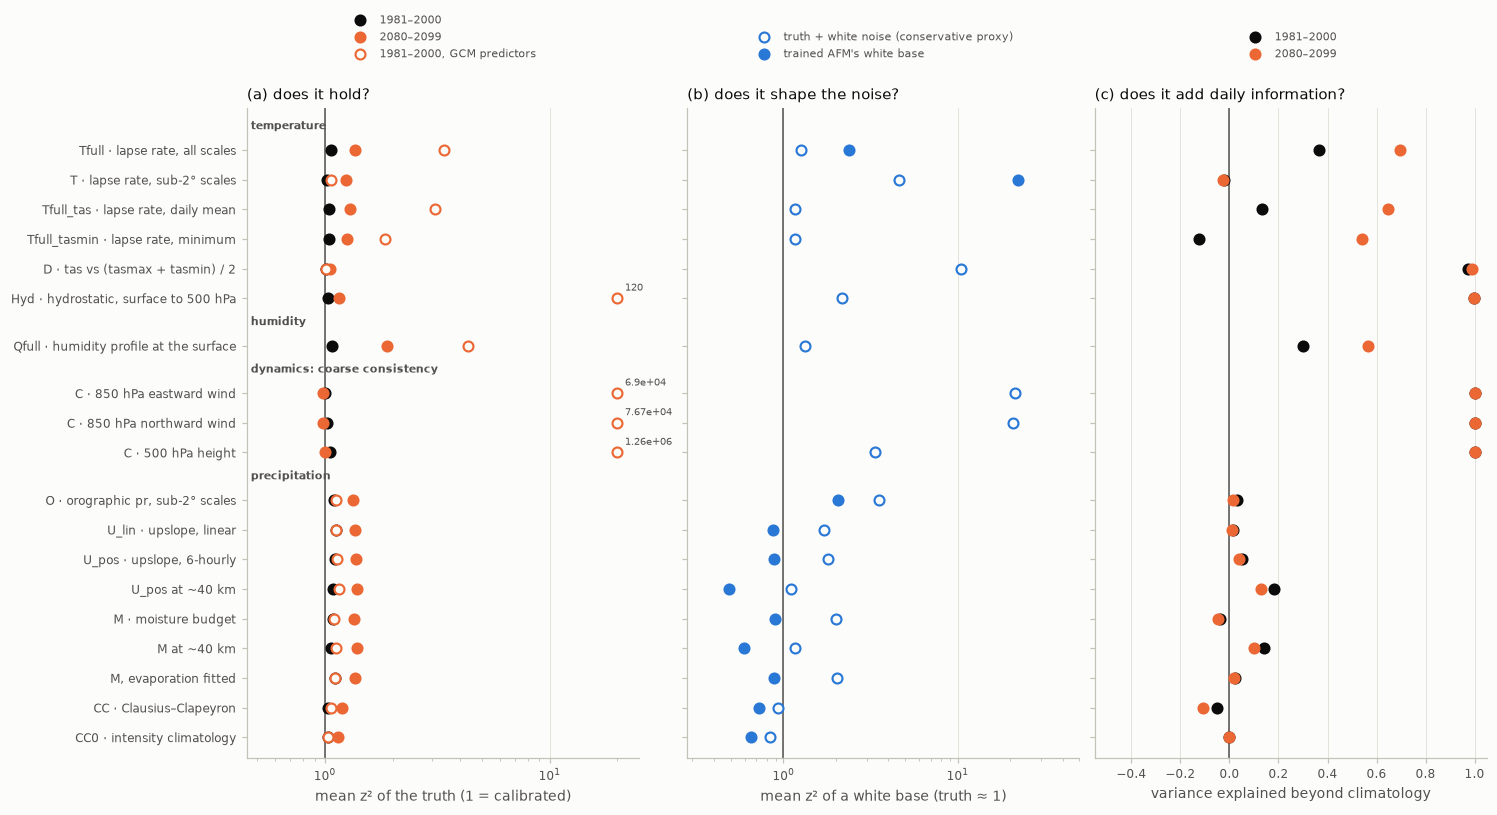

In [4]:
def card():
    rows = []
    for g, laws in GROUPS.items():
        for n in laws:
            d = ALL.sel(law=n)
            sk = lambda s: float(SUM.loc[(n, s), "skill vs climatology"])  # noqa: E731
            rows.append({"law": n, "group": g, "title": P.LAW_TITLES.get(n, n),
                         "a_today": float(d.ms_z.sel(split="historical_perfect")),
                         "a_future": float(d.ms_z.sel(split="end_century_perfect")),
                         "a_gcm": float(d.ms_z.sel(split="historical_imperfect")),
                         "b_proxy": float(d.ms_z_white.sel(split="historical_perfect")),
                         "b_afm": float(d.ms_z_afmbase.sel(split="historical_perfect")),
                         "c_today": sk("historical_perfect"), "c_future": sk("end_century_perfect")})
    return pd.DataFrame(rows).set_index("law")


CARD = card()
caption("one row per law; (a) mean squared normalised residual of the truth (1 = tolerance calibrated); (b) the same "
        "for a white base: truth plus white noise at the conservative noise proxy (hollow) and the trained AFM's "
        "white base E + σε (filled, pr and tasmax laws); (c) variance explained beyond the training-years monthly "
        "climatology. Values outside the axes are printed.", "1981–2000 and 2080–2099 (RCM predictors), 1981–2000 (GCM "
        "predictors)")
P.fig_law_scorecard(CARD, save=save("scorecard"))
plt.show()
display(CARD.reset_index().set_index(["group", "law"]).drop(columns="title").style.format(fmt))

**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **Four laws pass all three criteria with RCM predictors:** Tfull (and its `tas` variant), the coarse consistency C,
  the hydrostatic law Hyd and the diurnal-mean law D. C, Hyd and D are exact, but they need other 12 km fields to be
  generated with pr and tasmax (C: `ua850`, `va850`, `zg500`; Hyd: `zg500`, `ps`, `tas`, `huss`; D: `tas`, `tasmin`).
* **T** holds and shapes the noise more than any other pr or tasmax law (white AFM base: mean $z^2$ = 22 against the
  truth's 1.03), but it adds no daily information (skill −0.02).
* **Precipitation:** no law adds daily information (skill ≤ 0.05 at 12 km, ≤ 0.18 at 40 km), and the trained AFM's
  base already satisfies the pointwise laws better than the truth does (mean $z^2$ 0.87–0.89): their tolerance
  (6.6–6.9 mm/day) is wider than the base's noise. Only O, a high-pass law, is violated by the white base (2.0 AFM,
  3.5 proxy).
* **GCM predictors** break every law that relies on the coarse state: C (mean $z^2$ ~10⁵–10⁶), Hyd (120), Qfull
  (4.3), Tfull (3.4). The precipitation laws barely change (1.10–1.16), because they barely use the predictors.

## 4. (a) Does the law hold? Calibration, tails and drift

For every day and grid point: residual $r = Jx - (J\varphi + c_m)$ and normalised residual $z = r/\tau_m$. On the training
years mean $z^2 = 1$ by construction; on the other splits it should stay near 1, and $\alpha = \sqrt{\overline{z^2}}$ is
the factor by which the tolerance would have to grow. A mean residual that departs from zero in another climate is
**drift**: the law, with its training offsets, is biased there, and conditioning would pull the base towards that bias.

**Shown:** mean squared normalised residual per split and the inflation α = √(mean z²).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

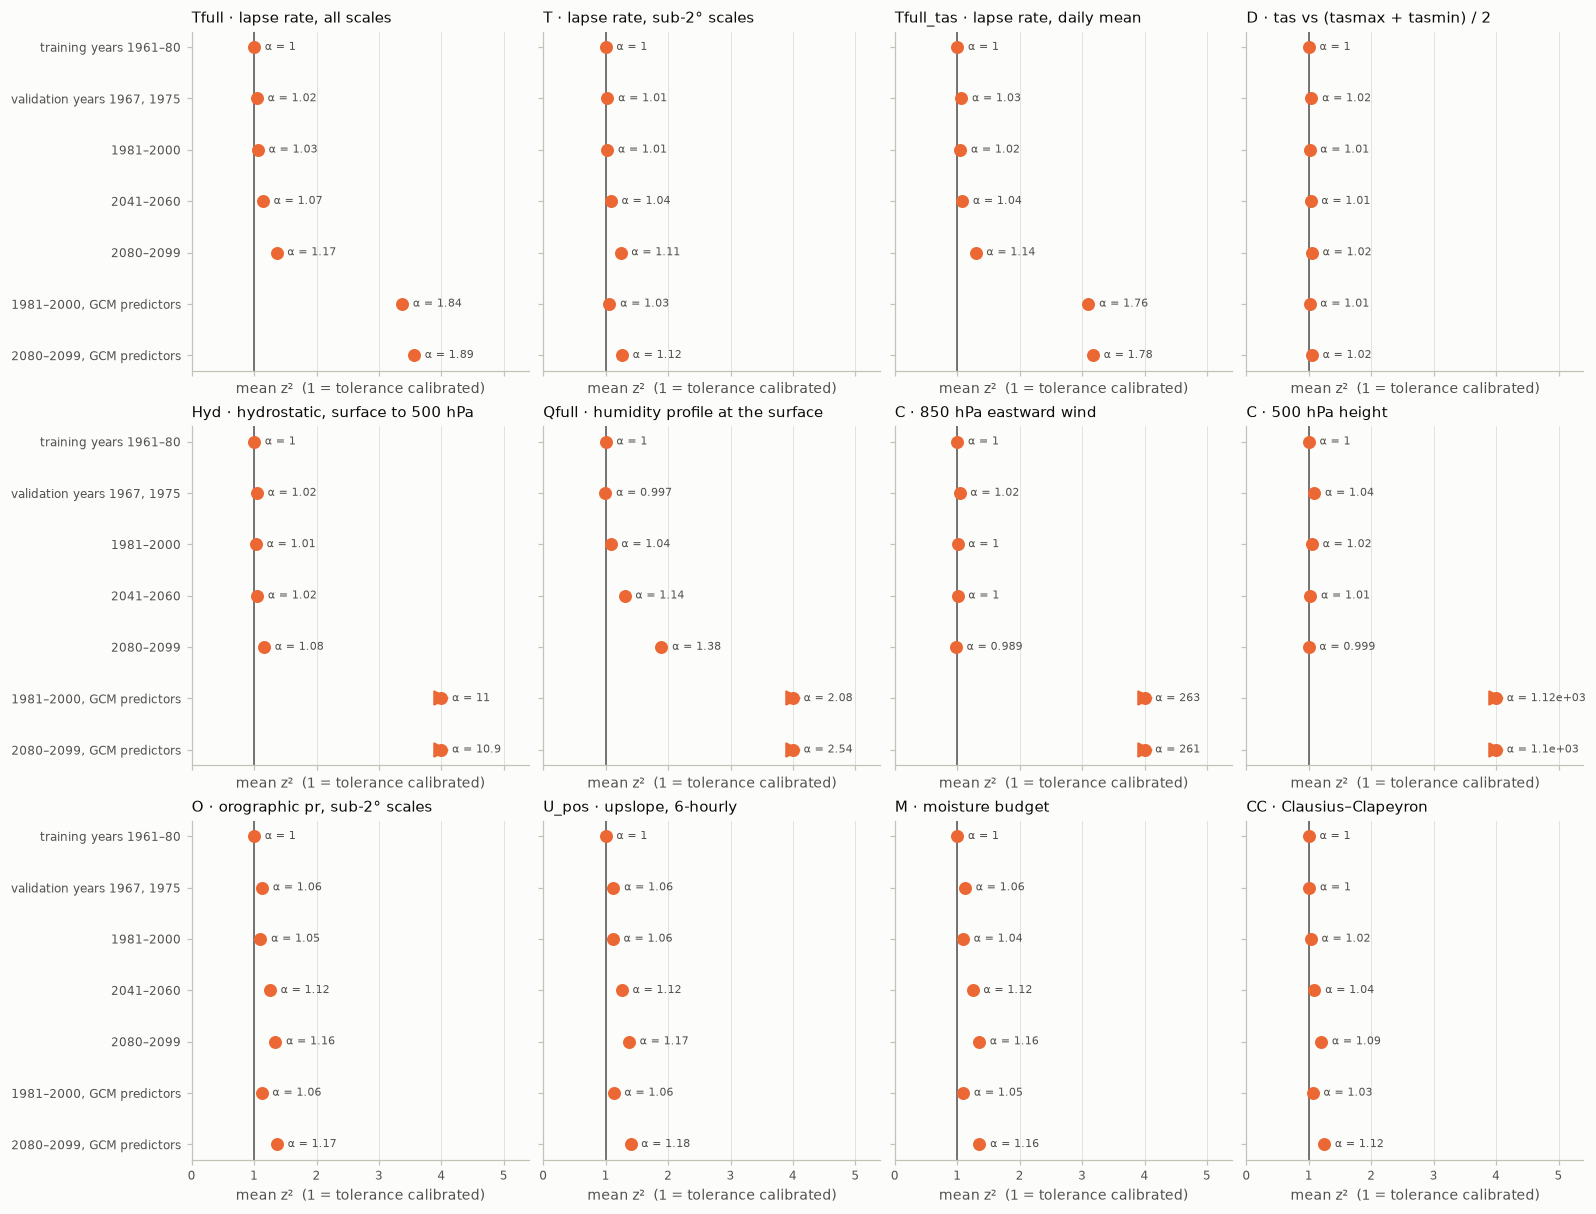

In [5]:
SHOW = ['Tfull', 'T', 'Tfull_tas', 'D', 'Hyd', 'Qfull', 'C_u850', 'C_z500', 'O', 'U_pos', 'M', 'CC']
SUB = ALL.sel(law=SHOW)
SUBSUM = SUM.loc[SHOW]
caption("mean squared normalised residual per split and the inflation α = √(mean z²).", "every split")
P.fig_law_calibration(SUBSUM, save=save("calibration"))
plt.show()

**Shown:** density of the normalised residual (log scale) against the standard normal.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** training years, 2080–2099 with RCM and with GCM predictors

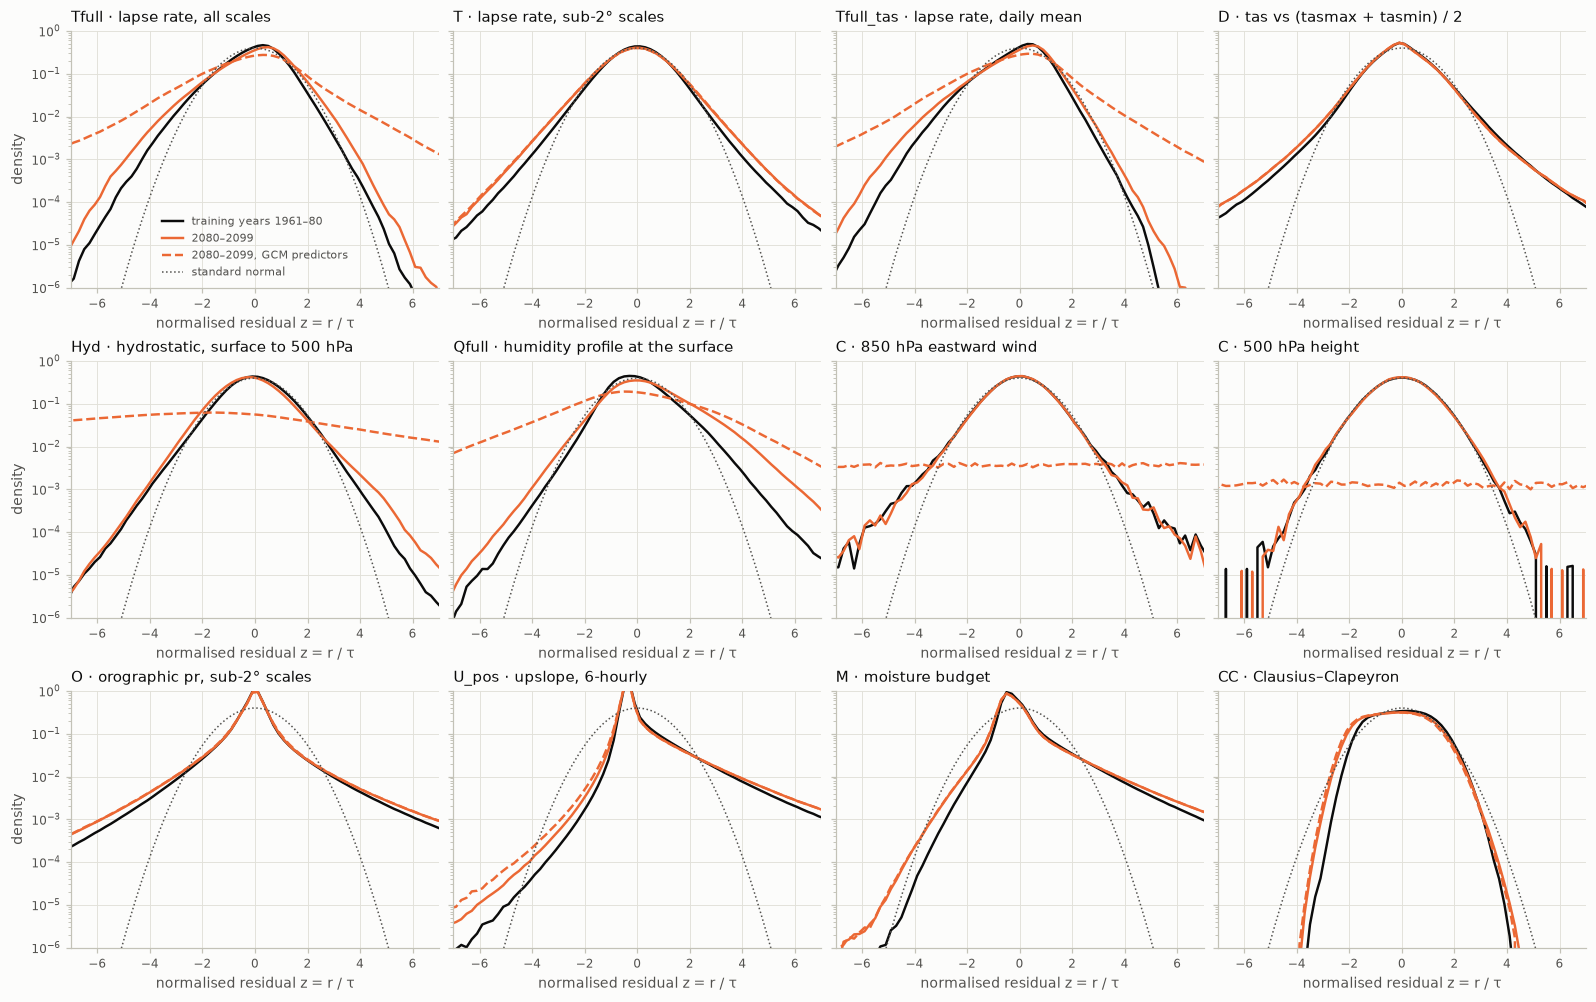

In [6]:
caption("density of the normalised residual (log scale) against the standard normal.",
        "training years, 2080–2099 with RCM and with GCM predictors")
P.fig_law_z_hist(SUB, ["train", "end_century_perfect", "end_century_imperfect"], save=save("z_hist"))
plt.show()

**Shown:** RMS over grid points of the truth's monthly-mean residual: how far the training offsets are off in each month (0 on the training years; partly sampling noise on the 2-year validation set).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

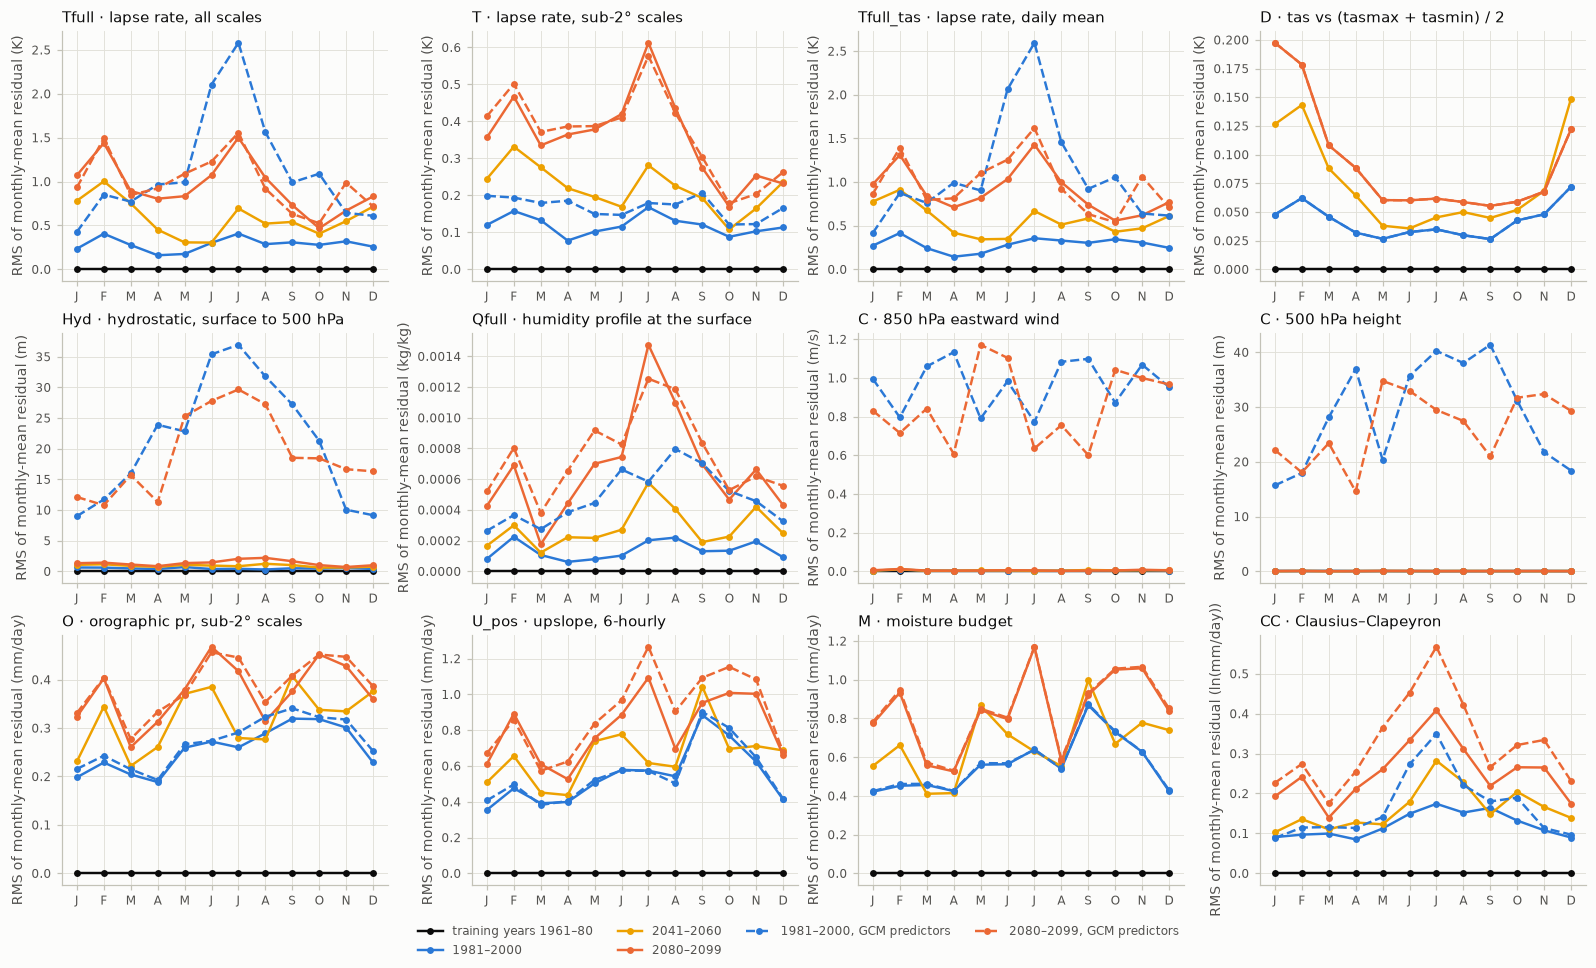

In [7]:
caption("RMS over grid points of the truth's monthly-mean residual: how far the training offsets are off in each "
        "month (0 on the training years; partly sampling noise on the 2-year validation set).", "every split")
P.fig_law_monthly(SUB, "drift_rms_month", [s for s in SPLITS if s != "val"], "RMS of monthly-mean residual ({units})",
                  save=save("drift_monthly"))
plt.show()

**Shown:** June–August mean residual of the truth in 2080–2099 (truth − law; precipitation: blue = wetter than the law).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** 2080–2099, RCM predictors

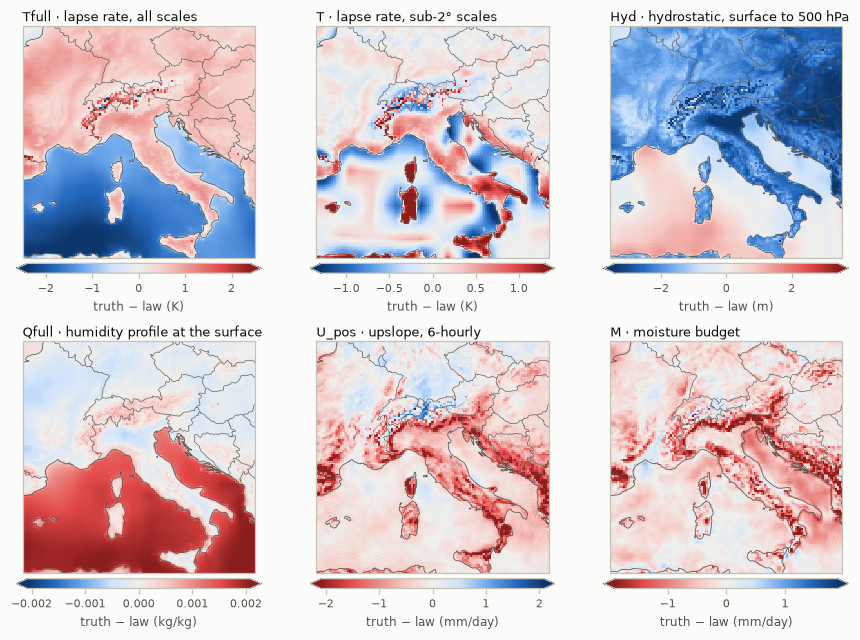

In [8]:
caption("June–August mean residual of the truth in 2080–2099 (truth − law; precipitation: blue = wetter than the law).",
        "2080–2099, RCM predictors")
panels = []
for n in ["Tfull", "T", "Hyd", "Qfull", "U_pos", "M"]:
    f = ALL.bias_map_jja.sel(law=n, split="end_century_perfect").values
    lim = P.robust_abs([f])
    cmap = P.DIV["pr"] if P.LAW_UNITS[n] == "mm/day" else P.DIV["tasmax"]
    panels.append(dict(field=f, title=P.LAW_TITLES[n], cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim),
                       label=f"truth − law ({P.LAW_UNITS[n]})", extend="both"))
P.fig_law_maps(panels, MG, ncols=3, save=save("drift_maps"))
plt.show()

In [9]:
caption("change of the mean wet-day intensity against the training years (domain mean of the truth's mean residual of "
        "ln P): CC0 = actual change, CC-implied = Clausius–Clapeyron scaling at the coarse 850 hPa temperature.",
        "all splits")
rows = {}
for s in SPLITS:
    b0, bc = float(ALL.bias.sel(law="CC0", split=s)), float(ALL.bias.sel(law="CC", split=s))
    rows[s] = {"actual change": 100 * np.expm1(b0), "CC-implied change": 100 * np.expm1(b0 - bc),
               "actual / CC-implied": b0 / (b0 - bc) if abs(b0 - bc) > 1e-3 else np.nan}
display(pd.DataFrame(rows).T.rename(index=P.SPLIT_LABELS).style.format(
    {"actual change": "{:+.1f} %", "CC-implied change": "{:+.1f} %", "actual / CC-implied": "{:.2f}"}))

**Shown:** change of the mean wet-day intensity against the training years (domain mean of the truth's mean residual of ln P): CC0 = actual change, CC-implied = Clausius–Clapeyron scaling at the coarse 850 hPa temperature.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** all splits

,actual change,CC-implied change,actual / CC-implied
training years 1961–80,-0.0 %,-0.0 %,nan
"validation years 1967, 1975",+0.2 %,-3.1 %,-0.06
1981–2000,+0.8 %,+1.4 %,0.60
2041–2060,+4.8 %,+14.0 %,0.35
2080–2099,+7.4 %,+29.8 %,0.27
"1981–2000, GCM predictors",+0.8 %,+10.8 %,0.08
"2080–2099, GCM predictors",+7.4 %,+39.4 %,0.21


**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **Unseen years, same climate:** mean $z^2$ = 0.99–1.13 for every law on the validation years and in 1981–2000
  ($\alpha \le 1.06$): tolerances fitted on 18 training years transfer.
* **2080–2099, RCM predictors:** the exact laws stay calibrated (C 0.98–1.00, D 1.05) and Hyd nearly (1.16). The
  temperature and humidity laws drift: Tfull 1.36 ($\alpha$ = 1.17), T 1.24, Tfull_tas 1.30, Qfull 1.89 ($\alpha$ = 1.38).
  The precipitation laws reach 1.34–1.39 (CC 1.20), mostly because precipitation becomes more variable: the squared
  departure from the training climatology grows by 18% as well.
* **Where the drift sits:** Tfull's June–August residual in 2080–2099 is +0.10 K over land and −1.57 K over the sea
  (domain −0.25 K): the sea surface warms less than the free troposphere above it, so the training-climate offsets are
  too warm there (map above; same for Tfull_tas, Tfull_tasmin). T drifts by at most 0.6 K (monthly RMS), Hyd by −1.7 m
  over land (tolerance 5 m). The precipitation laws are 0.38 mm/day too wet in summer (U_pos, M): the RCM's summer
  drying is not in them.
* **GCM predictors (1981–2000):** Tfull's summer residual is −2.0 K (the GCM's free troposphere is warmer than the RCM's),
  $\alpha$ = 1.84 over the year; Hyd −34 m and C_z500 −37 m in summer (the GCM's 500 hPa height against the RCM's),
  C_u850 +0.7 m/s. A law that is exact for perfect predictors is then wrong by the GCM–RCM mismatch (section 1).
* **Clausius–Clapeyron:** the mean wet-day intensity grows by 7.4% by 2080–2099, the CC scaling at the coarse 850 hPa
  temperature implies 29.8% (ratio 0.27). Daily intensity does not follow CC here, and CC has negative daily skill.

## 5. (b) Does conditioning change the base?

The white base $E + \sigma\varepsilon$ adds independent noise at every grid point. That noise violates any law that
relates neighbouring points, scales or variables, whether or not the law carries daily information. Conditioning
removes the violating part of the noise (and pulls the mean towards the law), so the base starts near the truth's law
level. A law is worth conditioning on when a white base violates it **much more than the truth does** (mean $z^2 \gg 1$).

Two white bases are evaluated:
* **the trained AFM's white base** (`afm-base`, $E + \sigma_{\max}\varepsilon$, member 0) for the pr and tasmax laws;
* **truth + white noise** for every law, with a conservative noise level per generated field: the RMS of the sub-2°
  part of its daily anomaly about the training climatology, i.e. what neither the predictors nor the climatology
  supply. It assumes a perfect encoder and is therefore a lower bound; AFM's actual noise is larger (tasmax: 2.38 K
  against the proxy below).

The weight with which the base follows a pointwise law is $w = s^2/(s^2 + \tau^2)$ ($s$ the prior noise): a law much
sharper than the prior noise ($\tau \ll s$) dominates the base, a vague one ($\tau \gtrsim s$) barely moves it.

In [10]:
display(pd.Series(NOISE, name="conservative noise proxy s").to_frame().style.format(fmt).set_caption(
    "noise level per generated field (physical units)"))
tab = pd.DataFrame({"truth (1981–2000)": ALL.ms_z.sel(split="historical_perfect").to_pandas(),
                    "truth + white noise": ALL.ms_z_white.sel(split="historical_perfect").to_pandas(),
                    "AFM white base": ALL.ms_z_afmbase.sel(split="historical_perfect").to_pandas()})
tab["ratio (proxy / truth)"] = tab["truth + white noise"] / tab["truth (1981–2000)"]
display(tab.reindex([n for g in GROUPS.values() for n in g]).style.format(fmt).set_caption("mean z², 1981–2000"))

,conservative noise proxy s
tasmax,0.974
pr,3.661
evspsbl,0.732
huss,0.000383
ps,48.1
quas,0.00933
qvas,0.00819
tas,0.745
tasmin,1.026
ua850,1.146


,truth (1981–2000),truth + white noise,AFM white base,ratio (proxy / truth)
law,,,,
Tfull,1.060,1.263,2.379,1.191
T,1.025,4.635,22.2,4.522
Tfull_tas,1.048,1.167,,1.114
Tfull_tasmin,1.043,1.163,,1.115
D,1.011,10.5,,10.4
Hyd,1.030,2.163,,2.101
Qfull,1.080,1.331,,1.233
C_u850,1.005,21.3,,21.2
C_v850,1.027,20.8,,20.3


**Shown:** per month (training years, domain RMS): day-to-day signal of the law's target, tolerance τ, and the trained AFM's prior noise σ_max (dashed).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** training years

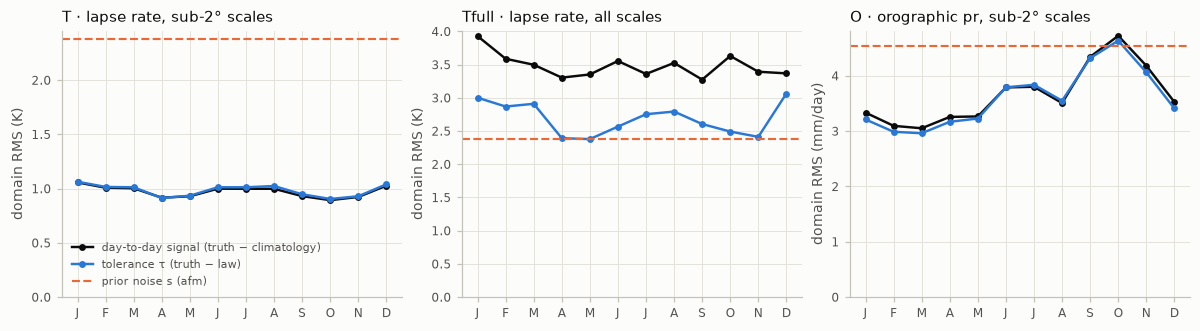

**Shown:** annual-mean tolerance τ (top) and the weight w = s² / (s² + τ²) with AFM's prior noise (bottom).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** training years

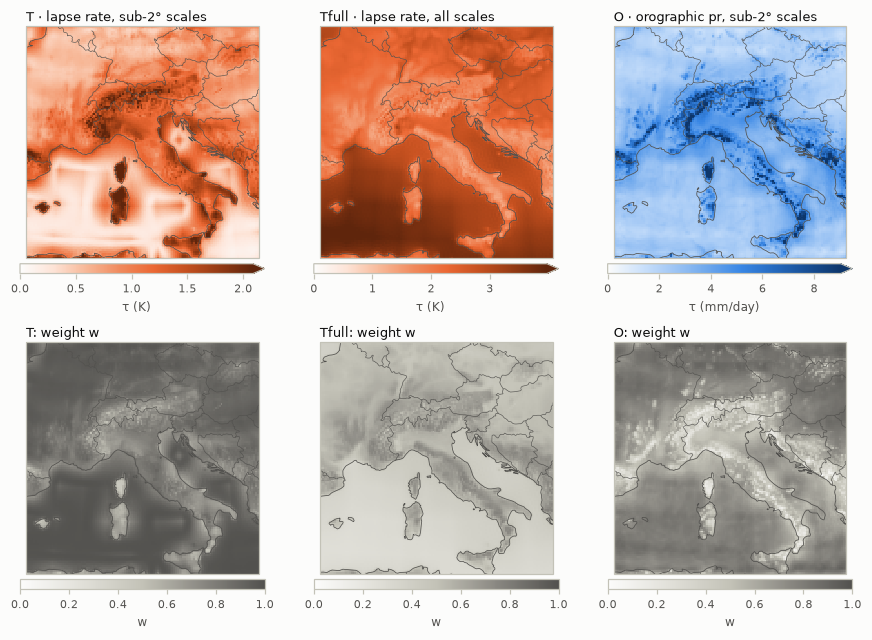

In [11]:
caption("per month (training years, domain RMS): day-to-day signal of the law's target, tolerance τ, and the "
        "trained AFM's prior noise σ_max (dashed).", "training years")
P.fig_law_sizes(D1, save=save("sizes"))
plt.show()
caption("annual-mean tolerance τ (top) and the weight w = s² / (s² + τ²) with AFM's prior noise (bottom).", "training years")
panels = []
for n in D1.law.values:
    tol = np.sqrt((D1.tol.sel(law=n) ** 2).mean("month")).values
    cmap = P.SEQ["pr"] if D1.law_variable.sel(law=n) == "pr" else P.SEQ["tasmax"]
    panels.append(dict(field=tol, title=P.LAW_TITLES[n], cmap=cmap, norm=Normalize(0, np.nanpercentile(tol, 99)),
                       label=f"τ ({P.LAW_UNITS[n]})", extend="max"))
for n in D1.law.values:
    panels.append(dict(field=D1.weight.sel(law=n).mean("month").values, title=f"{n}: weight w", cmap=GREY,
                       norm=Normalize(0, 1), label="w"))
P.fig_law_maps(panels, MG, save=save("tolerance_maps"))
plt.show()

**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **Noise levels.** The conservative proxy is 0.97 K for tasmax and 3.66 mm/day for pr; the trained AFM's prior noise
  $\sigma_{\max}$ is 2.38 K and 4.54 mm/day (2.4 and 1.2 times the proxy).
* **Ratio white base / truth, 1981–2000 (proxy):** C_u850, C_v850 21; D 10.5; T 4.6; O 3.5; C_z500 3.3; Hyd 2.2; the
  12 km precipitation laws 1.7–2.0; Qfull 1.33; Tfull 1.26; Tfull_tas, Tfull_tasmin 1.17; 40 km laws 1.11–1.16; CC 0.93.
  With AFM's actual base: T 22, Tfull 2.4, O 2.0, and **below 1** for the pointwise precipitation laws (0.87–0.89; 40 km
  0.49–0.59; CC 0.72).
* **Pattern.** Independent noise at every point has no scale or cross-variable structure, so it violates most the laws
  that compare scales (T and O: the sub-2° part; C: the 2° mean, with a tolerance of 0.03–0.04 m/s) or variables (D). A
  pointwise law with a wide tolerance is barely touched; for pr the base's smooth mean and moderate noise already lie
  inside the tolerance band, so conditioning cannot reshape the base, and (section 6) its pull on the mean hurts.
* **Weights.** With AFM's prior noise the mean weight $w$ is 0.87 for T, 0.69 for O and 0.49 for Tfull: T would
  dominate the sub-2° part of the tasmax base, Tfull would set about half of it.
* **Calibration of the tolerance is what matters for (b):** $\tau$ is fitted so the truth scores 1, so a white base
  scoring $\gg 1$ means the conditioning moves the noise towards the truth's law level. The comparison uses the
  same $\tau$; with $\tau$ inflated by $\alpha$ for another climate the ratios shrink by $\alpha^2$.

## 6. (c) Does the law add daily information?

**Skill beyond climatology** $= 1 - \overline{(Jx - b)^2}\,/\,\overline{(Jx - \bar x^{clim}_m)^2}$, where $b$ is the law's
prediction for the day and $\bar x^{clim}_m$ the truth's own training-years monthly mean at that grid point (a fixed
map per month). The denominator is the day-to-day weather; the score is the share of it that the law reproduces: 0 =
no better than the fixed monthly map, 1 = every daily departure, < 0 = the law's daily variation is noise. A law can
*hold* well (small residual) and still score 0 if its agreement comes from the climatological pattern alone; T is the
example (83% of its sub-2° variance is explained, all of it by the monthly pattern). In a warmer climate the baseline is
still the *training* climatology, so the score includes the climate-change signal.

Daily information matters for the base's **mean**, which is the encoder estimate: a law can only improve it where the
encoder is wrong. The stronger test conditions the trained AFM encoder's estimate on the law and scores the conditioned
mean against the encoder itself (pr and tasmax laws; pointwise precipitation laws with the RCM's own wind, oracle).

**Shown:** variance explained beyond climatology per split; filled: law as used, hollow: physics alone (without the fitted offset; missing where meaningless).  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

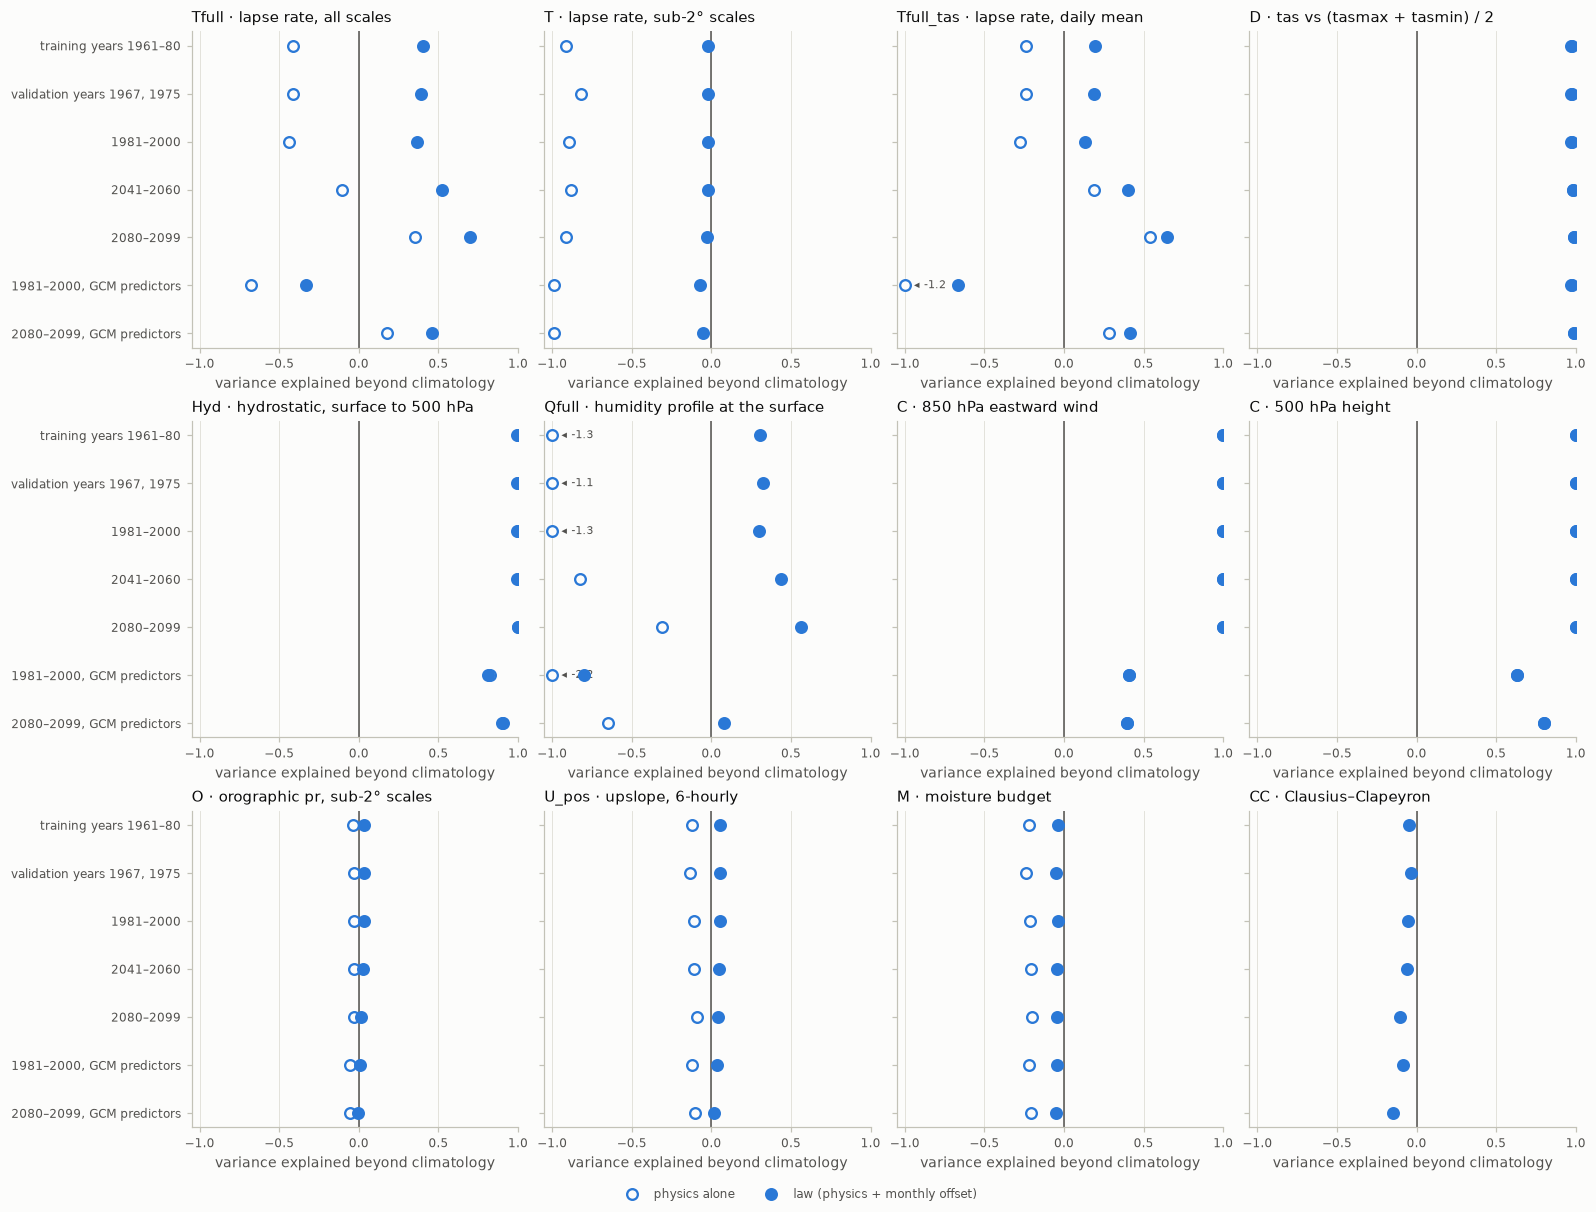

In [12]:
caption("variance explained beyond climatology per split; filled: law as used, hollow: physics alone (without the "
        "fitted offset; missing where meaningless).", "every split")
P.fig_law_skill(SUBSUM, save=save("skill"))
plt.show()

In [13]:
caption("the trained AFM encoder's estimate E and E conditioned on each law (posterior mean with the prior noise "
        "σ_max): RMSE and June–August bias against the truth.", "validation years, every 10th day of 1981–2000 and 2080–2099")
v = VAL.pivot_table(index=["variable", "field"], columns="split", values=["RMSE", "JJA bias"], sort=False)
v = v.reindex(columns=["val", "historical_perfect", "end_century_perfect"], level=1)
display(v.rename(columns=P.SPLIT_LABELS).style.format("{:.3f}"))

**Shown:** the trained AFM encoder's estimate E and E conditioned on each law (posterior mean with the prior noise σ_max): RMSE and June–August bias against the truth.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** validation years, every 10th day of 1981–2000 and 2080–2099

**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **Skill beyond climatology** (1981–2000 → 2080–2099): Tfull 0.37 → 0.70, Tfull_tas 0.13 → 0.65, Tfull_tasmin −0.12 →
  0.54, Qfull 0.30 → 0.56. In the warmer climate most of the score is the warming signal, which the coarse
  free-atmosphere temperature and humidity carry. With GCM predictors these laws score below 0 (Tfull −0.33, Qfull −0.80).
* The exact laws score 1.00 (C, perfect predictors), 0.998 (Hyd) and 0.97 (D), all oracle: D and Hyd draw their
  information from other generated fields. With GCM predictors C still explains 0.41 (u850), 0.45 (v850) and 0.63
  (z500) of the RCM's daily 2° variability: informative, but far from exact.
* **T −0.02, O 0.03:** the sub-2° laws hold through their monthly pattern alone.
* **Precipitation:** at most 0.05 at 12 km (U_pos 0.05, U_lin 0.02, M_Efit 0.02, M −0.04, CC −0.05) and 0.14–0.18 at
  40 km (M_40km, U_pos_40km), 0.10–0.13 in 2080–2099. Even with the RCM's own 6-hourly wind and humidity, terrain
  ascent and moisture convergence explain at most 18% of the daily precipitation variability at 40 km.
* **The conditioned encoder mean** answers the practical question. Tfull lowers AFM's tasmax RMSE by 11% (2.39 → 2.14 K
  on the validation years, 2.35 → 2.11 K in 1981–2000) and by 13% in 2080–2099 (2.57 → 2.23 K), where it cuts the
  summer bias from −0.87 to −0.28 K. T lowers the RMSE by 2.5–2.8% and leaves the bias unchanged (high-pass). **Every
  precipitation law makes the encoder's pr worse:** O by 2% (4.62 → 4.70 mm/day), U_lin, U_pos and M by 8% (4.62 →
  5.00–5.02). The encoder already knows more about the day's precipitation than any of these laws, even with oracle
  winds.

## 7. The primitive equations

Coti Zelati, Huang, Kukavica, Temam & Ziane (2015, *Nonlinearity* 28, 625, eqs. 2.11–2.16) write the moist primitive
equations in pressure coordinates ($\omega = dp/dt$, $\omega^- = \max(-\omega, 0)$ the ascent, $H$ the Heaviside graph,
$q_s$ the saturation humidity, $F$ a saturation function):

$$\partial_t\mathbf v + (\mathbf v\cdot\nabla)\mathbf v + \omega\,\partial_p\mathbf v + f\,\mathbf k\times\mathbf v + \nabla\Phi
+ \mathcal A_v\mathbf v = \mathbf S_v \qquad \partial_p\Phi + RT/p = 0 \qquad \nabla\cdot\mathbf v + \partial_p\omega = 0$$
$$\partial_t T + \mathbf v\cdot\nabla T + \omega\,\partial_p T - \tfrac{R}{c_p p}\,\omega T + \mathcal A_T T \in
\tfrac{L}{c_p p}\,\omega^- H(q - q_s)\,F(T) + S_T$$
$$\partial_t q + \mathbf v\cdot\nabla q + \omega\,\partial_p q + \mathcal A_q q \in -\tfrac1p\,\omega^- H(q - q_s)\,F(T) + S_q$$

Condensation is a sink of vapour only in rising, saturated air; if the condensate falls out at once, precipitation is
its column integral. **What the data allow.** The equations are instantaneous and three-dimensional. The only 3-D state
we have is the daily 2° predictors (u, v, t, z, q at three levels, no ω); at 12 km the archive holds surface fields,
the 850 hPa wind and the 500 hPa height on different levels, daily or 6-hourly:

| equation | at 2° (predictors, daily) | at 12 km (archive) |
|---|---|---|
| hydrostatic (2.12) | testable: thickness between levels | testable: surface to 500 hPa (law **Hyd**) |
| momentum (2.11) | testable without $\omega\,\partial_p\mathbf v$ and friction | not testable (no wind and height on the same level) |
| continuity (2.13) | only defines ω (no ω to test against) | not testable |
| temperature (2.14) | needs ω and the heating; not tested | not testable |
| humidity (2.15) | layer budget 850–500 hPa without ω and the layer below 850 hPa | surface layer only (law **M**) |

Derivatives are centred differences (on the sphere at 2°, the true grid spacing at 12 km) and, in time, differences
of neighbouring days; daily means of products (advection, fluxes) differ from products of daily means, which adds
an error the instantaneous equations do not have.

In [14]:
caption("hydrostatic balance at 2°: thickness z(top) − z(bottom) against (R_d/g) T̄ ln(p_bottom/p_top), with temperature "
        "and with virtual temperature; RMSE relative to the RMS of the daily thickness anomalies.", "every split")
h = PRIM[PRIM.test == "P-hyd"].pivot_table(index="item", columns="split", values="relative RMSE", sort=False)
display(h[[s for s in SPLITS if s in h.columns]].rename(columns=P.SPLIT_LABELS).style.format("{:.3f}"))
caption("horizontal momentum at 2°: RMS of the terms (m s⁻²) and of the residual, geostrophic balance alone and with "
        "the daily tendency and the horizontal advection, relative to the pressure-gradient term.", "every split")
m = PRIM[PRIM.test == "P-mom"].set_index(["item", "split"])
cols = ["RMS pressure gradient", "RMS tendency", "RMS advection", "residual / pressure gradient (geostrophic)",
        "residual / pressure gradient (with tendency + advection)"]
display(m[cols].rename(index=P.SPLIT_LABELS).style.format("{:.2e}", subset=cols[:3]).format("{:.3f}", subset=cols[3:]))
caption("humidity equation integrated over 850–500 hPa (−∂W/∂t − ∇·Q, one fitted gain) against the RCM's 2° "
        "precipitation.", "every split")
q = PRIM[PRIM.test == "P-hum"].set_index("split")[["gain", "mean budget (mm/day)", "mean precipitation (mm/day)",
                                                   "corr of daily anomalies", "skill vs climatology"]]
display(q.rename(index=P.SPLIT_LABELS).style.format("{:.3f}"))

**Shown:** hydrostatic balance at 2°: thickness z(top) − z(bottom) against (R_d/g) T̄ ln(p_bottom/p_top), with temperature and with virtual temperature; RMSE relative to the RMS of the daily thickness anomalies.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

split,training years 1961–80,"validation years 1967, 1975",1981–2000,2041–2060,2080–2099,"1981–2000, GCM predictors","2080–2099, GCM predictors"
item,,,,,,,
"thickness 850-700 hPa, T",0.184,0.191,0.183,0.202,0.221,0.184,0.233
"thickness 850-700 hPa, T_v",0.098,0.106,0.096,0.096,0.095,0.076,0.084
"thickness 700-500 hPa, T",0.164,0.170,0.162,0.173,0.178,0.160,0.188
"thickness 700-500 hPa, T_v",0.118,0.122,0.115,0.119,0.119,0.105,0.113


**Shown:** horizontal momentum at 2°: RMS of the terms (m s⁻²) and of the residual, geostrophic balance alone and with the daily tendency and the horizontal advection, relative to the pressure-gradient term.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

,,RMS pressure gradient,RMS tendency,RMS advection,residual / pressure gradient (geostrophic),residual / pressure gradient (with tendency + advection)
item,split,,,,,
850 hPa,training years 1961–80,1.01e-03,5.27e-05,1.43e-04,0.266,0.248
700 hPa,training years 1961–80,1.21e-03,5.92e-05,1.68e-04,0.189,0.159
500 hPa,training years 1961–80,1.73e-03,8.23e-05,2.92e-04,0.186,0.148
850 hPa,"validation years 1967, 1975",1.00e-03,5.35e-05,1.43e-04,0.270,0.253
700 hPa,"validation years 1967, 1975",1.19e-03,5.91e-05,1.64e-04,0.190,0.162
500 hPa,"validation years 1967, 1975",1.70e-03,8.22e-05,2.85e-04,0.186,0.151
850 hPa,1981–2000,1.03e-03,5.32e-05,1.45e-04,0.262,0.245
700 hPa,1981–2000,1.23e-03,5.95e-05,1.70e-04,0.187,0.157
500 hPa,1981–2000,1.76e-03,8.32e-05,2.94e-04,0.186,0.147


**Shown:** humidity equation integrated over 850–500 hPa (−∂W/∂t − ∇·Q, one fitted gain) against the RCM's 2° precipitation.  
**Laws fitted on:** the training years 1961–1980 (without 1967 and 1975), RCM truth and predictors  
**Evaluated on:** every split

,gain,mean budget (mm/day),mean precipitation (mm/day),corr of daily anomalies,skill vs climatology
split,,,,,
training years 1961–80,0.310,0.416,2.946,0.258,0.066
"validation years 1967, 1975",0.310,0.427,3.110,0.254,0.063
1981–2000,0.310,0.438,2.985,0.254,0.065
2041–2060,0.310,0.419,3.107,0.247,0.060
2080–2099,0.310,0.377,3.006,0.252,0.062
"1981–2000, GCM predictors",0.310,0.267,2.985,-0.016,-0.062
"2080–2099, GCM predictors",0.310,0.290,3.006,-0.005,-0.068


**Findings** *(snapshot 2026-11-03; update when laws or data change)*

* **Hydrostatic (2.12)** holds at 2° with virtual temperature: the thickness error is 10–12% of the daily thickness
  variability (correlation 0.999), 16–22% with $T$. The $T_v$ correction matters more in a moister climate (850–700
  hPa with $T$: 0.18 → 0.22 by 2080–2099; with $T_v$ 0.10 throughout). The GCM's fields are as hydrostatic (0.08–0.11).
  At 12 km (law Hyd, surface to 500 hPa) the skill is 0.998 and calibrated in every climate with RCM predictors; with
  GCM predictors the RCM's 12 km `zg500` and the GCM's upper levels disagree by 20–35 m.
* **Momentum (2.11)** at 2°: geostrophic balance leaves 18–19% of the pressure-gradient force unbalanced at 700 and 500 hPa
  and 26–27% at 850 hPa; the daily tendency and horizontal advection reduce that to 14–16% and 24–25%. The rest is
  vertical advection $\omega\,\partial_p\mathbf v$ (no $\omega$), friction (850 hPa is close to or below ground over
  the Alps), daily means of products and 2° differencing. At 12 km it cannot be tested: the archive has no wind and
  height on the same level.
* **Humidity (2.15) with continuity**, over 850–500 hPa: the daily anomalies of $-\partial_t W - \nabla\cdot\mathbf Q$
  correlate 0.25 with the RCM's 2° precipitation (skill 0.06, gain 0.31), and not at all with GCM predictors (−0.02).
  The layer's mean convergence is 0.42 mm/day, 14% of the mean precipitation (2.95 mm/day): most of the condensed
  vapour enters from below 850 hPa, where most of the water is, through the vertical flux $\omega q$ we cannot compute.
* **Temperature (2.14) and continuity (2.13)** need $\omega$ and the diabatic heating; not testable.
* **Feasibility.** The equations are instantaneous and three-dimensional; LC-AFM generates daily, single-level fields.
  Only the hydrostatic equation survives as a 12 km law, and it is nonlinear in the generated fields ($T_v$, $\ln p_s$),
  so it needs linearisation about the encoder estimate. Momentum and humidity would need several 12 km levels of
  u, v, z, q and sub-daily output, i.e. generating a 3-D atmosphere; with this archive they can be checked only at 2°,
  where the predictors already supply them. For precipitation, the only primitive-equation link is the humidity
  sink, and its daily signal sits in the boundary layer and in $\omega$, neither of which is available.

## 8. Summary and recommendations

**Findings** *(snapshot 2026-11-03; update when laws or data change)*

| law | generated fields | (a) mean $z^2$: 1981–2000 / 2080–2099 / GCM | (b) white base: AFM / proxy | (c) skill: 1981–2000 → 2080–2099 | conditioned encoder mean | linear | verdict |
|---|---|---|---|---|---|---|---|
| **Tfull** | tasmax | 1.06 / 1.36 / 3.37 | 2.4 / 1.26 | 0.37 → 0.70 | RMSE −11%, summer bias −0.87 → −0.28 K (2080–2099) | yes | **keep**; inflate $\tau$ (~1.8×) for GCM predictors; sea drift |
| **T** | tasmax (sub-2°) | 1.03 / 1.24 / 1.06 | 22 / 4.6 | −0.02 | RMSE −2.5 to −2.8% | yes | **keep as noise shaper**, ideally together with Tfull |
| O | pr (sub-2°) | 1.10 / 1.34 / 1.12 | 2.0 / 3.5 | 0.03 | RMSE +2% | yes | weak: shapes the noise, harms the mean |
| **C** (u850, v850, z500) | ua850, va850, zg500 | 1.00–1.05 / 0.98–1.00 / ~10⁵–10⁶ | – / 21, 21, 3.3 | 1.00 (GCM: 0.41–0.63) | – | yes | **keep if these fields are generated**; $\tau$ from the GCM–RCM mismatch for GCM predictors |
| C for pr, tasmax | pr, tasmax | exact by construction (perfect); GCM pr: relative RMSE 1.0 | – | pins 61% / 89% of the daily variability, 74% / 99% of the 2080–2099 change | – | yes | strongest pr law, but needs a coarse pr / tasmax input the benchmark does not have |
| D | tas, tasmax, tasmin | 1.01 / 1.05 / 1.01 | – / 10.5 | 0.97 → 0.99 | – | yes | keep if `tas`, `tasmin` are generated |
| Hyd | zg500, ps, tas, huss | 1.03 / 1.16 / 120 | – / 2.2 | 0.998 | – | after linearisation | possible with joint generation |
| Tfull_tas, Tfull_tasmin | tas, tasmin | 1.04–1.05 / 1.25–1.30 / 1.85–3.10 | – / 1.17 | 0.13 / −0.12 → 0.65 / 0.54 | – | yes | as Tfull, if generated |
| Qfull | huss | 1.08 / 1.89 / 4.32 | – / 1.33 | 0.30 → 0.56 | – | yes | weak, drifts |
| U_lin, U_pos, M, M_Efit | pr (+ wind, humidity, evaporation) | 1.09–1.12 / 1.35–1.37 / 1.10–1.13 | 0.87–0.89 / 1.7–2.0 | ≤ 0.05 | RMSE +8% | U_lin only | drop |
| U_pos_40km, M_40km | pr (+ wind, humidity) | 1.07–1.09 / 1.38–1.39 / 1.12–1.16 | 0.49–0.59 / 1.11–1.16 | 0.14–0.18 → 0.10–0.13 | – | no | drop (best precipitation law, still weak) |
| CC | ln pr on wet days | 1.03 / 1.20 / 1.06 | 0.72 / 0.93 | −0.05 | – | no | drop: intensity +7%, CC implies +30% |

**Recommendations**
1. **Tfull + T for tasmax.** Tfull is the only law that passes all three criteria for a benchmark variable; T adds
   the strongest noise shaping on the sub-2° scales. Conditioning on both at once ($J = [I; H]$ on the same channel)
   is not possible in the current implementation, which takes one law per channel; this is a small extension.
2. **Precipitation needs either a coarse counterpart or other generated fields.** No law built from the predictors
   and the terrain constrains daily pr usefully, even with oracle winds. The one strong precipitation law is coarse
   consistency (61% of the daily variability pinned), which requires a coarse precipitation input (section 1): a
   design decision that leaves the benchmark protocol, and with GCM inputs the counterpart is poor.
3. **Joint generation** of `ua850`, `va850`, `zg500` (with C), `tas`, `tasmin` (with D, Tfull variants) and, with a
   linearisation, `zg500`/`ps`/`huss` (with Hyd) gives exact, strongly noise-shaping laws. Their value for pr is
   indirect (a physically consistent joint sample) and can only be measured by training.
4. **Imperfect predictors:** every law tied to the coarse state needs its tolerance widened to the GCM–RCM mismatch
   ($\tau$ ×260–280 for C_u850, C_v850, ×1100 for C_z500, ×1.8 for Tfull), or the conditioning weakens to the climatology.
5. **Primitive equations:** only the hydrostatic equation is usable at 12 km (Hyd). Momentum and the humidity budget
   need multi-level, sub-daily 12 km fields that this archive does not have.